In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [ ]:
import pandas as pd

# Read Excel without headers
df = pd.read_excel("Shelf Life dataset (1).xlsx", header=None)

# Use row 3 as column names
df.columns = df.iloc[3]

# Keep only the actual data (starts at row 5)
df = df.iloc[5:]

# Remove the empty first column
df = df.drop(columns=[df.columns[0]])

# Reset the index
df = df.reset_index(drop=True)

# Display the cleaned data
df

3,DAY,MOISTURE,pH,ACIDITY,WATER ACTIVITY,COLOUR,TPC,YEAST & MOLD,SENSORY SCORE
0,0,11.88,6.4,1.05,0.708,"32.3, 8.1, 14.0",100,10,9.2
1,7,12,6.38,1.07,0.712,"32.2, 8.0, 13.9",105,12,9.1
2,14,12.2,6.35,1.09,0.716,"32.1, 8.0, 13.8",115,14,9
3,21,12.5,6.32,1.11,0.722,"32.0, 7.9, 13.7",130,18,8.9
4,28,12.8,6.28,1.13,0.73,"31.9, 7.9, 13.7",160,22,8.8
5,35,13.1,6.24,1.16,0.738,"31.8, 7.9, 13.6",190,28,8.6
6,42,13.4,6.2,1.18,0.746,"31.6, 7.8, 13.5",230,35,8.4
7,49,13.7,6.15,1.21,0.755,"31.4, 7.7, 13.2",280,45,8.2
8,56,14,6.1,1.23,0.765,"31.3, 7.7, 13.1",330,55,8


In [ ]:
df

3,DAY,MOISTURE,pH,ACIDITY,WATER ACTIVITY,COLOUR,TPC,YEAST & MOLD,SENSORY SCORE
0,0,11.88,6.4,1.05,0.708,"32.3, 8.1, 14.0",100,10,9.2
1,7,12,6.38,1.07,0.712,"32.2, 8.0, 13.9",105,12,9.1
2,14,12.2,6.35,1.09,0.716,"32.1, 8.0, 13.8",115,14,9
3,21,12.5,6.32,1.11,0.722,"32.0, 7.9, 13.7",130,18,8.9
4,28,12.8,6.28,1.13,0.73,"31.9, 7.9, 13.7",160,22,8.8
5,35,13.1,6.24,1.16,0.738,"31.8, 7.9, 13.6",190,28,8.6
6,42,13.4,6.2,1.18,0.746,"31.6, 7.8, 13.5",230,35,8.4
7,49,13.7,6.15,1.21,0.755,"31.4, 7.7, 13.2",280,45,8.2
8,56,14,6.1,1.23,0.765,"31.3, 7.7, 13.1",330,55,8


In [ ]:
df.head()

3,DAY,MOISTURE,pH,ACIDITY,WATER ACTIVITY,COLOUR,TPC,YEAST & MOLD,SENSORY SCORE
0,0,11.88,6.4,1.05,0.708,"32.3, 8.1, 14.0",100,10,9.2
1,7,12,6.38,1.07,0.712,"32.2, 8.0, 13.9",105,12,9.1
2,14,12.2,6.35,1.09,0.716,"32.1, 8.0, 13.8",115,14,9
3,21,12.5,6.32,1.11,0.722,"32.0, 7.9, 13.7",130,18,8.9
4,28,12.8,6.28,1.13,0.73,"31.9, 7.9, 13.7",160,22,8.8


In [ ]:
df.shape

(9, 9)

In [ ]:
df.columns

Index([               nan,              'DAY',         'MOISTURE',
                     'pH',          'ACIDITY', 'WATER   ACTIVITY',
               'COLOUR  ',              'TPC',    'YEAST &  MOLD',
        'SENSORY   SCORE'],
      dtype='object', name=3)

In [ ]:
df.columns = [
    "DAY",
    "MOISTURE",
    "PH",
    "ACIDITY",
    "WATER_ACTIVITY",
    "COLOUR",
    "TPC",
    "YEAST_MOLD",
    "SENSORY_SCORE"
]

In [ ]:
df.columns

Index(['DAY', 'MOISTURE', 'PH', 'ACIDITY', 'WATER_ACTIVITY', 'COLOUR', 'TPC',
       'YEAST_MOLD', 'SENSORY_SCORE'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   DAY             9 non-null      object
 1   MOISTURE        9 non-null      object
 2   PH              9 non-null      object
 3   ACIDITY         9 non-null      object
 4   WATER_ACTIVITY  9 non-null      object
 5   COLOUR          9 non-null      object
 6   TPC             9 non-null      object
 7   YEAST_MOLD      9 non-null      object
 8   SENSORY_SCORE   9 non-null      object
dtypes: object(9)
memory usage: 780.0+ bytes


In [ ]:
df.isnull().sum()

,0
DAY,0
MOISTURE,0
PH,0
ACIDITY,0
WATER_ACTIVITY,0
COLOUR,0
TPC,0
YEAST_MOLD,0
SENSORY_SCORE,0


In [ ]:
colour = df["COLOUR"].str.split(",", expand=True)

df["L"] = colour[0].astype(float)
df["A"] = colour[1].astype(float)
df["B"] = colour[2].astype(float)

In [ ]:
df = df.drop("COLOUR", axis=1)

In [ ]:
df.head()

,DAY,MOISTURE,PH,ACIDITY,WATER_ACTIVITY,TPC,YEAST_MOLD,SENSORY_SCORE,L,A,B
0,0,11.88,6.4,1.05,0.708,100,10,9.2,32.3,8.1,14.0
1,7,12,6.38,1.07,0.712,105,12,9.1,32.2,8.0,13.9
2,14,12.2,6.35,1.09,0.716,115,14,9,32.1,8.0,13.8
3,21,12.5,6.32,1.11,0.722,130,18,8.9,32.0,7.9,13.7
4,28,12.8,6.28,1.13,0.73,160,22,8.8,31.9,7.9,13.7


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   DAY             9 non-null      object 
 1   MOISTURE        9 non-null      object 
 2   PH              9 non-null      object 
 3   ACIDITY         9 non-null      object 
 4   WATER_ACTIVITY  9 non-null      object 
 5   TPC             9 non-null      object 
 6   YEAST_MOLD      9 non-null      object 
 7   SENSORY_SCORE   9 non-null      object 
 8   L               9 non-null      float64
 9   A               9 non-null      float64
 10  B               9 non-null      float64
dtypes: float64(3), object(8)
memory usage: 924.0+ bytes


In [ ]:
df.isnull().sum()

,0
DAY,0
MOISTURE,0
PH,0
ACIDITY,0
WATER_ACTIVITY,0
TPC,0
YEAST_MOLD,0
SENSORY_SCORE,0
L,0
A,0


In [ ]:
df.head()

,DAY,MOISTURE,PH,ACIDITY,WATER_ACTIVITY,TPC,YEAST_MOLD,SENSORY_SCORE,L,A,B
0,0,11.88,6.4,1.05,0.708,100,10,9.2,32.3,8.1,14.0
1,7,12,6.38,1.07,0.712,105,12,9.1,32.2,8.0,13.9
2,14,12.2,6.35,1.09,0.716,115,14,9,32.1,8.0,13.8
3,21,12.5,6.32,1.11,0.722,130,18,8.9,32.0,7.9,13.7
4,28,12.8,6.28,1.13,0.73,160,22,8.8,31.9,7.9,13.7


In [ ]:
columns = [
    "DAY",
    "MOISTURE",
    "PH",
    "ACIDITY",
    "WATER_ACTIVITY",
    "TPC",
    "YEAST_MOLD",
    "SENSORY_SCORE"
]

for col in columns:
    df[col] = pd.to_numeric(df[col])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   DAY             9 non-null      int64  
 1   MOISTURE        9 non-null      float64
 2   PH              9 non-null      float64
 3   ACIDITY         9 non-null      float64
 4   WATER_ACTIVITY  9 non-null      float64
 5   TPC             9 non-null      int64  
 6   YEAST_MOLD      9 non-null      int64  
 7   SENSORY_SCORE   9 non-null      float64
 8   L               9 non-null      float64
 9   A               9 non-null      float64
 10  B               9 non-null      float64
dtypes: float64(8), int64(3)
memory usage: 924.0 bytes


In [ ]:
df.describe()

,DAY,MOISTURE,PH,ACIDITY,WATER_ACTIVITY,TPC,YEAST_MOLD,SENSORY_SCORE,L,A,B
count,9.00000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000
mean,28.00000,12.842222,6.268889,1.136667,0.732444,182.222222,26.555556,8.688889,31.844444,7.888889,13.611111
std,19.17029,0.759963,0.104337,0.062650,0.019951,82.314607,15.653363,0.416667,0.350397,0.136423,0.301846
min,0.00000,11.880000,6.100000,1.050000,0.708000,100.000000,10.000000,8.000000,31.300000,7.700000,13.100000
25%,14.00000,12.200000,6.200000,1.090000,0.716000,115.000000,14.000000,8.400000,31.600000,7.800000,13.500000
50%,28.00000,12.800000,6.280000,1.130000,0.730000,160.000000,22.000000,8.800000,31.900000,7.900000,13.700000
75%,42.00000,13.400000,6.350000,1.180000,0.746000,230.000000,35.000000,9.000000,32.100000,8.000000,13.800000
max,56.00000,14.000000,6.400000,1.230000,0.765000,330.000000,55.000000,9.200000,32.300000,8.100000,14.000000


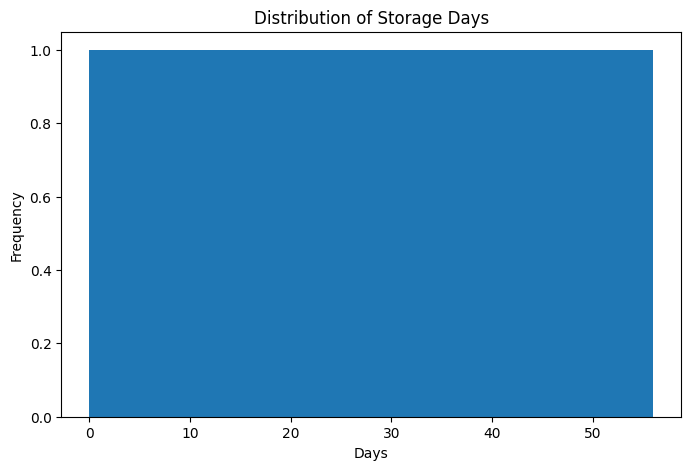

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df["DAY"], bins=9)

plt.title("Distribution of Storage Days")
plt.xlabel("Days")
plt.ylabel("Frequency")

plt.show()

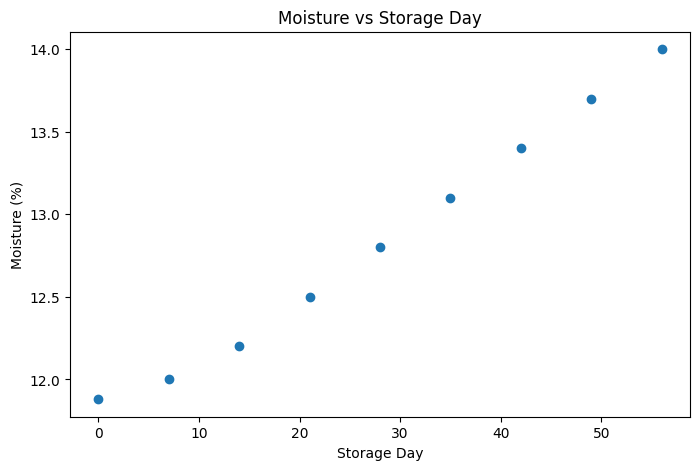

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(df["DAY"], df["MOISTURE"])

plt.title("Moisture vs Storage Day")
plt.xlabel("Storage Day")
plt.ylabel("Moisture (%)")

plt.show()

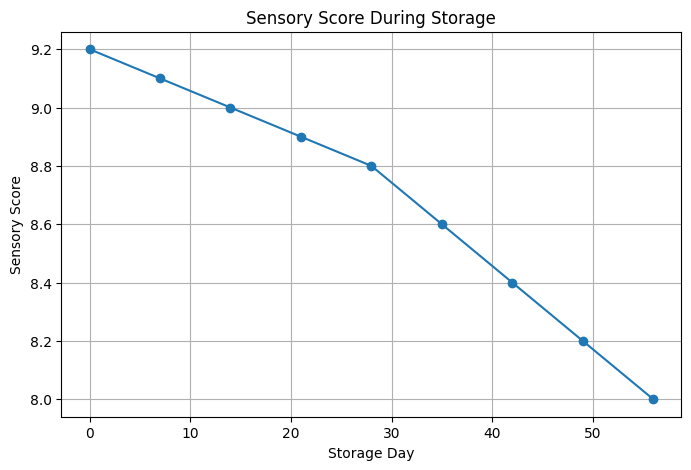

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(df["DAY"], df["SENSORY_SCORE"], marker="o")

plt.title("Sensory Score During Storage")

plt.xlabel("Storage Day")

plt.ylabel("Sensory Score")

plt.grid(True)

plt.show()

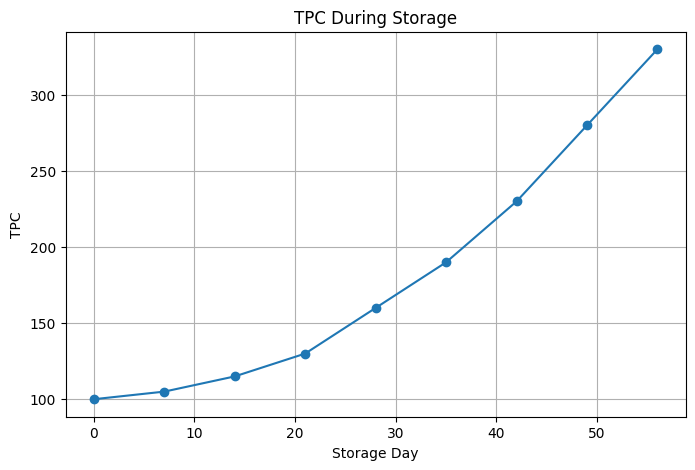

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(df["DAY"], df["TPC"], marker="o")

plt.title("TPC During Storage")

plt.xlabel("Storage Day")

plt.ylabel("TPC")

plt.grid(True)

plt.show()

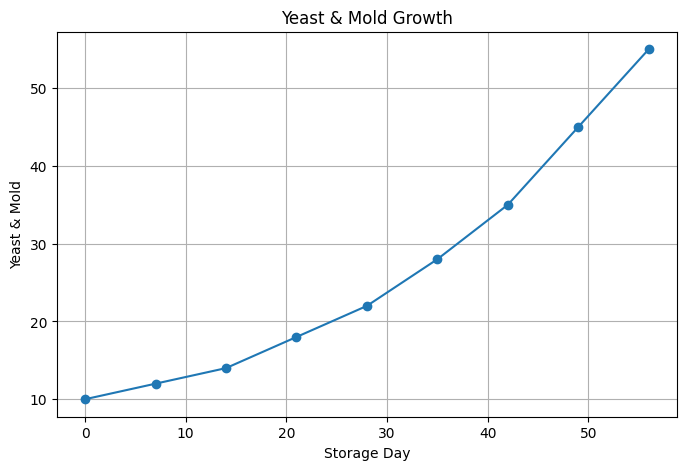

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(df["DAY"], df["YEAST_MOLD"], marker="o")

plt.title("Yeast & Mold Growth")

plt.xlabel("Storage Day")

plt.ylabel("Yeast & Mold")

plt.grid(True)

plt.show()

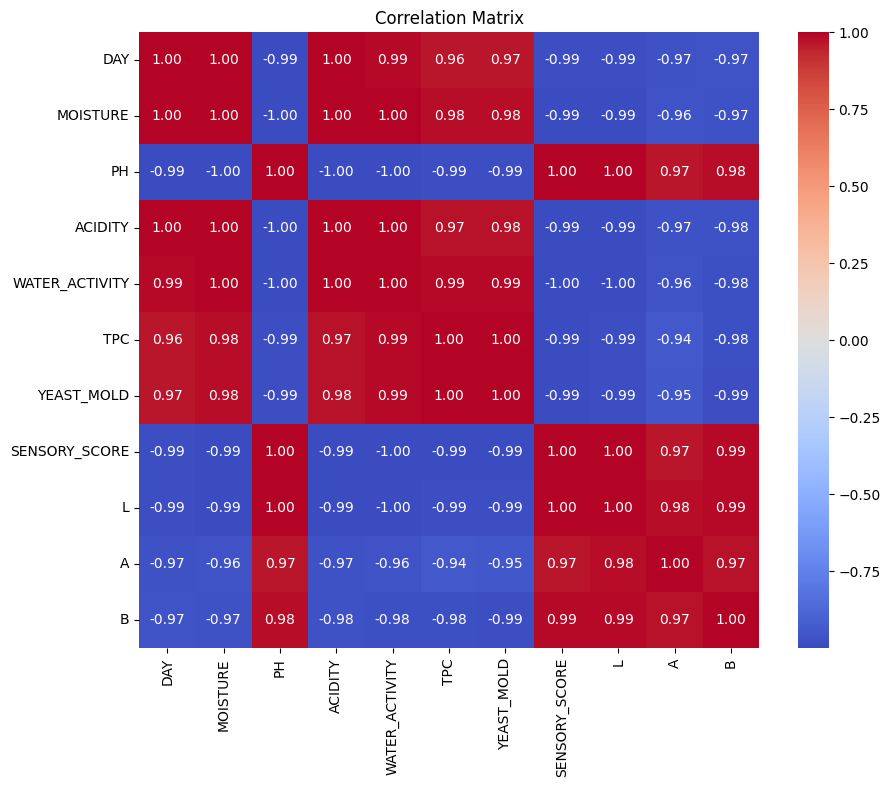

In [ ]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(10,8))

sns.heatmap(corr,
            annot=True,
            cmap="coolwarm",
            fmt=".2f")

plt.title("Correlation Matrix")

plt.show()

In [ ]:
X = df.drop("DAY", axis=1)
y = df["DAY"]

In [ ]:
print(X.head())

   MOISTURE    PH  ACIDITY  WATER_ACTIVITY  TPC  YEAST_MOLD  SENSORY_SCORE  \
0     11.88  6.40     1.05           0.708  100          10            9.2   
1     12.00  6.38     1.07           0.712  105          12            9.1   
2     12.20  6.35     1.09           0.716  115          14            9.0   
3     12.50  6.32     1.11           0.722  130          18            8.9   
4     12.80  6.28     1.13           0.730  160          22            8.8   

      L    A     B  
0  32.3  8.1  14.0  
1  32.2  8.0  13.9  
2  32.1  8.0  13.8  
3  32.0  7.9  13.7  
4  31.9  7.9  13.7  


In [ ]:
print(y.head())

0     0
1     7
2    14
3    21
4    28
Name: DAY, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import numpy as np

In [ ]:
X = df.drop("DAY", axis=1)

y = df["DAY"]

In [ ]:
loo = LeaveOneOut()

In [ ]:
actual = []
predicted = []

In [ ]:
model = LinearRegression()

for train_index, test_index in loo.split(X):

    X_train = X.iloc[train_index]
    X_test = X.iloc[test_index]

    y_train = y.iloc[train_index]
    y_test = y.iloc[test_index]

    model.fit(X_train, y_train)

    prediction = model.predict(X_test)

    actual.append(y_test.values[0])
    predicted.append(prediction[0])

In [ ]:
results = pd.DataFrame({
    "Actual Day": actual,
    "Predicted Day": predicted
})

results

,Actual Day,Predicted Day
0,0,4.074259
1,7,3.946674
2,14,8.560393
3,21,25.058999
4,28,23.980558
5,35,33.141903
6,42,47.215328
7,49,55.604312
8,56,47.120535


In [ ]:
mae = mean_absolute_error(actual, predicted)

mse = mean_squared_error(actual, predicted)

rmse = np.sqrt(mse)

r2 = r2_score(actual, predicted)

print("MAE :", mae)

print("RMSE :", rmse)

print("R² Score :", r2)

MAE : 4.8003149556916345
RMSE : 5.177484343229883
R² Score : 0.9179397628845186


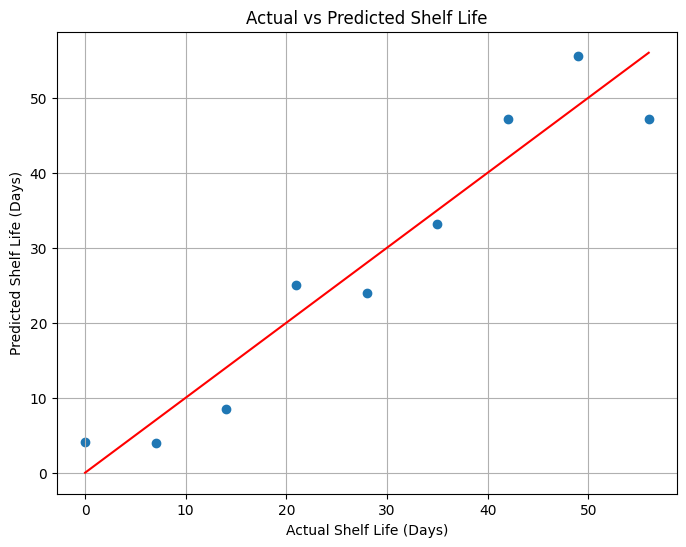

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(actual, predicted)

plt.plot(
    [min(actual), max(actual)],
    [min(actual), max(actual)],
    color='red'
)

plt.xlabel("Actual Shelf Life (Days)")

plt.ylabel("Predicted Shelf Life (Days)")

plt.title("Actual vs Predicted Shelf Life")

plt.grid(True)

plt.show()

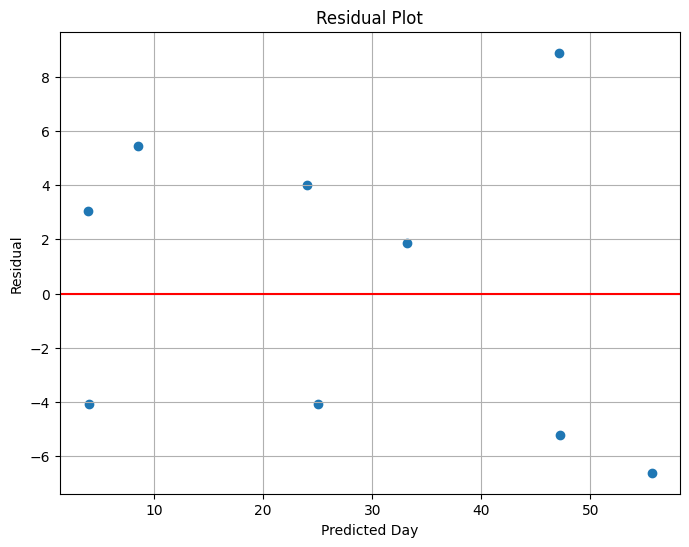

In [ ]:
residuals = np.array(actual) - np.array(predicted)

plt.figure(figsize=(8,6))

plt.scatter(predicted, residuals)

plt.axhline(0, color='red')

plt.xlabel("Predicted Day")

plt.ylabel("Residual")

plt.title("Residual Plot")

plt.grid(True)

plt.show()

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

importance = importance.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

importance

,Feature,Coefficient
2,ACIDITY,66.588747
6,SENSORY_SCORE,-53.666490
7,L,51.789520
8,A,-50.835722
1,PH,-43.096162
9,B,-41.611257
0,MOISTURE,21.544518
3,WATER_ACTIVITY,13.294429
5,YEAST_MOLD,-5.096831
4,TPC,0.585810


In [ ]:
X = df[
    [
        "MOISTURE",
        "PH",
        "ACIDITY",
        "WATER_ACTIVITY",
        "TPC",
        "YEAST_MOLD",
        "SENSORY_SCORE"
    ]
]

y = df["DAY"]

In [ ]:
from sklearn.tree import DecisionTreeRegressor

In [ ]:
from sklearn.model_selection import LeaveOneOut

loo = LeaveOneOut()

In [ ]:
actual_dt = []
predicted_dt = []

In [ ]:
model_dt = DecisionTreeRegressor(
    random_state=42,
    max_depth=3
)

for train_index, test_index in loo.split(X):

    X_train = X.iloc[train_index]
    X_test = X.iloc[test_index]

    y_train = y.iloc[train_index]
    y_test = y.iloc[test_index]

    model_dt.fit(X_train, y_train)

    prediction = model_dt.predict(X_test)

    actual_dt.append(y_test.values[0])
    predicted_dt.append(prediction[0])

In [ ]:
mae_dt = mean_absolute_error(actual_dt, predicted_dt)

rmse_dt = np.sqrt(
    mean_squared_error(actual_dt, predicted_dt)
)

r2_dt = r2_score(actual_dt, predicted_dt)

print("Decision Tree Results")
print("----------------------")
print("MAE :", mae_dt)
print("RMSE :", rmse_dt)
print("R² :", r2_dt)

Decision Tree Results
----------------------
MAE : 7.777777777777778
RMSE : 7.912718313646146
R² : 0.8083333333333333


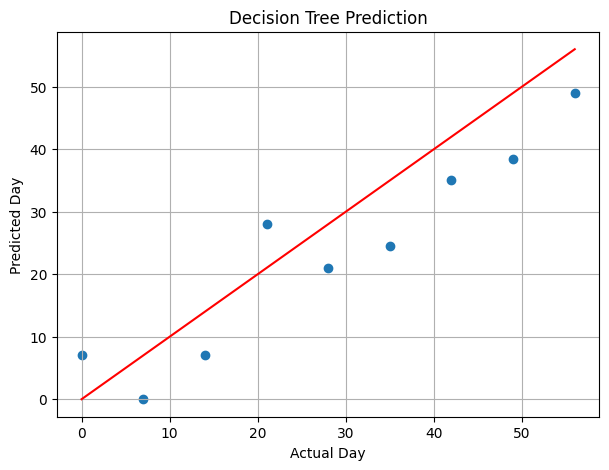

In [ ]:
plt.figure(figsize=(7,5))

plt.scatter(actual_dt, predicted_dt)

plt.plot(
    [0,56],
    [0,56],
    color="red"
)

plt.xlabel("Actual Day")

plt.ylabel("Predicted Day")

plt.title("Decision Tree Prediction")

plt.grid(True)

plt.show()

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
actual_rf = []
predicted_rf = []

In [ ]:
model_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    max_depth=3
)

for train_index, test_index in loo.split(X):

    X_train = X.iloc[train_index]
    X_test = X.iloc[test_index]

    y_train = y.iloc[train_index]
    y_test = y.iloc[test_index]

    model_rf.fit(X_train, y_train)

    prediction = model_rf.predict(X_test)

    actual_rf.append(y_test.values[0])
    predicted_rf.append(prediction[0])

In [ ]:
mae_rf = mean_absolute_error(actual_rf, predicted_rf)

rmse_rf = np.sqrt(
    mean_squared_error(actual_rf, predicted_rf)
)

r2_rf = r2_score(actual_rf, predicted_rf)

print("Random Forest Results")
print("----------------------")
print("MAE :", mae_rf)
print("RMSE :", rmse_rf)
print("R² :", r2_rf)

Random Forest Results
----------------------
MAE : 3.9934999999999983
RMSE : 5.151186888583164
R² : 0.9187712458333334


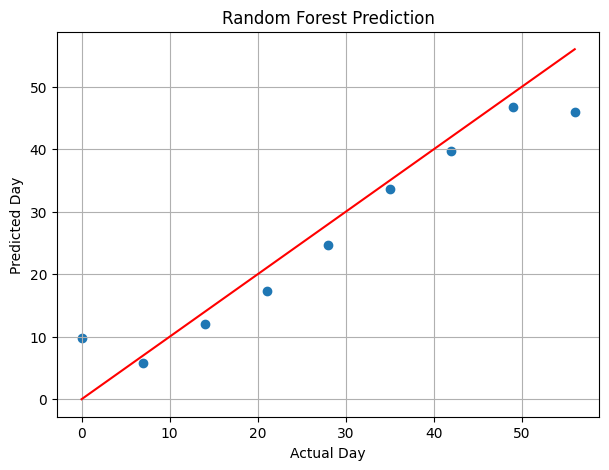

In [ ]:
plt.figure(figsize=(7,5))

plt.scatter(actual_rf, predicted_rf)

plt.plot(
    [0,56],
    [0,56],
    color="red"
)

plt.xlabel("Actual Day")
plt.ylabel("Predicted Day")
plt.title("Random Forest Prediction")

plt.grid(True)

plt.show()

In [ ]:
# ===============================
# AI-BASED SHELF LIFE PREDICTION
# ===============================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import LeaveOneOut
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# ===============================
# LOAD DATASET
# ===============================

from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_excel(filename)

print(df.head())

# ===============================
# CREATE NEW TARGET
# ===============================

MAX_STORAGE_DAYS = df["DAY"].max()

df["REMAINING_SHELF_LIFE"] = MAX_STORAGE_DAYS - df["DAY"]

print(df[["DAY","REMAINING_SHELF_LIFE"]])

# ===============================
# FEATURES
# ===============================

X = df[
[
"MOISTURE",
"PH",
"ACIDITY",
"WATER_ACTIVITY",
"TPC",
"YEAST_MOLD",
"SENSORY_SCORE"
]
]

y = df["REMAINING_SHELF_LIFE"]

# ===============================
# LOOCV FUNCTION
# ===============================

def evaluate_model(model):

    loo = LeaveOneOut()

    actual = []

    predicted = []

    for train_index, test_index in loo.split(X):

        X_train = X.iloc[train_index]
        X_test = X.iloc[test_index]

        y_train = y.iloc[train_index]
        y_test = y.iloc[test_index]

        model.fit(X_train, y_train)

        pred = model.predict(X_test)

        actual.append(y_test.values[0])
        predicted.append(pred[0])

    mae = mean_absolute_error(actual,predicted)

    rmse = np.sqrt(mean_squared_error(actual,predicted))

    r2 = r2_score(actual,predicted)

    return actual,predicted,mae,rmse,r2

# ===============================
# LINEAR REGRESSION
# ===============================

lr = LinearRegression()

actual_lr,pred_lr,mae_lr,rmse_lr,r2_lr = evaluate_model(lr)

# ===============================
# DECISION TREE
# ===============================

dt = DecisionTreeRegressor(
random_state=42,
max_depth=3
)

actual_dt,pred_dt,mae_dt,rmse_dt,r2_dt = evaluate_model(dt)

# ===============================
# RANDOM FOREST
# ===============================

rf = RandomForestRegressor(
n_estimators=100,
random_state=42,
max_depth=3
)

actual_rf,pred_rf,mae_rf,rmse_rf,r2_rf = evaluate_model(rf)

# ===============================
# MODEL COMPARISON
# ===============================

comparison = pd.DataFrame({

"Model":[
"Linear Regression",
"Decision Tree",
"Random Forest"
],

"MAE":[
mae_lr,
mae_dt,
mae_rf
],

"RMSE":[
rmse_lr,
rmse_dt,
rmse_rf
],

"R2":[
r2_lr,
r2_dt,
r2_rf
]

})

print("\nMODEL COMPARISON\n")

print(comparison)

# ===============================
# BEST MODEL
# ===============================

best_model = comparison.sort_values(
by="MAE"
).iloc[0]

print("\nBest Model\n")

print(best_model)

# ===============================
# TRAIN BEST MODEL
# ===============================

rf.fit(X,y)

# ===============================
# PREDICT REMAINING SHELF LIFE
# ===============================

predicted_days = rf.predict(X)

df["PREDICTED_REMAINING_DAYS"] = predicted_days

# ===============================
# SHELF LIFE STATUS
# ===============================

def shelf_status(days):

    if days > 14:
        return "Fresh"

    elif days > 0:
        return "Near Expiry"

    else:
        return "Expired"

df["STATUS"] = df["PREDICTED_REMAINING_DAYS"].apply(shelf_status)

# ===============================
# PRODUCT RECOMMENDATION
# ===============================

def recommendation(row):

    if row["STATUS"]=="Fresh":
        return "Suitable for storage"

    elif row["STATUS"]=="Near Expiry":
        return "Consume soon"

    else:
        return "Not recommended for consumption"

df["RECOMMENDATION"] = df.apply(
recommendation,
axis=1
)

# ===============================
# FINAL RESULTS
# ===============================

print("\nFINAL RESULTS\n")

print(

df[
[
"DAY",
"REMAINING_SHELF_LIFE",
"PREDICTED_REMAINING_DAYS",
"STATUS",
"RECOMMENDATION"
]
]

)

# ===============================
# ACTUAL VS PREDICTED
# ===============================

plt.figure(figsize=(7,5))

plt.scatter(
actual_rf,
pred_rf
)

plt.plot(
[min(actual_rf),max(actual_rf)],
[min(actual_rf),max(actual_rf)],
color="red"
)

plt.xlabel("Actual Remaining Shelf Life")

plt.ylabel("Predicted Remaining Shelf Life")

plt.title("Random Forest Prediction")

plt.grid(True)

plt.show()

# ===============================
# FEATURE IMPORTANCE
# ===============================

importance = pd.DataFrame({

"Feature":X.columns,

"Importance":rf.feature_importances_

})

importance = importance.sort_values(
by="Importance",
ascending=False
)

print("\nFeature Importance\n")

print(importance)

plt.figure(figsize=(8,5))

plt.bar(
importance["Feature"],
importance["Importance"]
)

plt.xticks(rotation=45)

plt.title("Random Forest Feature Importance")

plt.show()